# What Drives the Price of a Used Car?

# What drives the price of a car?

![](images/kurt.jpeg)



**OVERVIEW**

In this application, you will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing.  Your goal is to understand what factors make a car more or less expensive.  As a result of your analysis, you should provide clear recommendations to your client -- a used car dealership -- as to what consumers value in a used car.


### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>


To frame the task, throughout our practical applications, we will refer back to a standard process in industry for data projects called CRISP-DM.  This process provides a framework for working through a data problem.  Your first step in this application will be to read through a brief overview of CRISP-DM [here](https://mo-pcco.s3.us-east-1.amazonaws.com/BH-PCMLAI/module_11/readings_starter.zip).  After reading the overview, answer the questions below.

## Analysis roadmap

1. **Business understanding** — translate the dealership question into a supervised regression problem.
2. **Data understanding** — inspect schema, missingness, distributions, duplicates, cardinality, and implausible values.
3. **Data preparation** — remove leakage/identifier fields, filter extreme values, engineer vehicle age and mileage-per-year, group rare models, split the data, impute, encode, and scale.
4. **Modeling** — compare a median baseline, ordinary linear regression, Ridge, Lasso, and Random Forest; tune regularization using cross-validation.
5. **Evaluation** — compare holdout MAE, RMSE, and R²; inspect residuals, permutation importance, and interpretable Ridge coefficients.
6. **Deployment** — provide dealership recommendations, limitations, and a monitoring plan.

## 1. Business Understanding

We formulate the problem as supervised regression. Each row is a vehicle listing; `price` is the continuous response, and vehicle attributes are predictors. A useful model must do more than predict: it should quantify generalization error on unseen listings and provide stable, understandable price drivers.

**Success criteria**

- Beat a median-price baseline on a held-out test set.
- Use cross-validation for model selection rather than the test set.
- Report MAE in dollars as the primary metric because it is easy for dealers to interpret and less dominated by a few expensive listings than RMSE.
- Retain interpretable evidence about the direction and importance of vehicle attributes.

**Risks:** asking price is not sale price; omitted variables such as accident history and trim may matter; geographic and time shifts can weaken future performance.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)

 


## 2. Data Understanding

The checks below cover data types, missingness, duplicated records, numerical ranges, category cardinality, and target shape. These reveal which variables are usable and which integrity issues must be handled before modeling.

In [2]:
DATA_PATH =   'data/vehicles.csv'
data = pd.read_csv(DATA_PATH)
print(f'Data source: {DATA_PATH}')
print(f'Shape: {data.shape[0]:,} rows x {data.shape[1]} columns')
data.info()

Data source: data/vehicles.csv
Shape: 426,880 rows x 18 columns
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   region        426880 non-null  object 
 2   price         426880 non-null  int64  
 3   year          425675 non-null  float64
 4   manufacturer  409234 non-null  object 
 5   model         421603 non-null  object 
 6   condition     252776 non-null  object 
 7   cylinders     249202 non-null  object 
 8   fuel          423867 non-null  object 
 9   odometer      422480 non-null  float64
 10  title_status  418638 non-null  object 
 11  transmission  424324 non-null  object 
 12  VIN           265838 non-null  object 
 13  drive         296313 non-null  object 
 14  size          120519 non-null  object 
 15  type          334022 non-null  object 
 16  paint_color   296677 non-nul

In [3]:
print (data.head())

           id                  region  price  year manufacturer model  \
0  7222695916                prescott   6000   NaN          NaN   NaN   
1  7218891961            fayetteville  11900   NaN          NaN   NaN   
2  7221797935            florida keys  21000   NaN          NaN   NaN   
3  7222270760  worcester / central MA   1500   NaN          NaN   NaN   
4  7210384030              greensboro   4900   NaN          NaN   NaN   

  condition cylinders fuel  odometer title_status transmission  VIN drive  \
0       NaN       NaN  NaN       NaN          NaN          NaN  NaN   NaN   
1       NaN       NaN  NaN       NaN          NaN          NaN  NaN   NaN   
2       NaN       NaN  NaN       NaN          NaN          NaN  NaN   NaN   
3       NaN       NaN  NaN       NaN          NaN          NaN  NaN   NaN   
4       NaN       NaN  NaN       NaN          NaN          NaN  NaN   NaN   

  size type paint_color state  
0  NaN  NaN         NaN    az  
1  NaN  NaN         NaN    ar  
2 

In [4]:
schema = pd.DataFrame({
    'dtype': data.dtypes.astype(str),
    'missing_n': data.isna().sum(),
    'missing_pct': (100 * data.isna().mean()).round(1),
    'unique_n': data.nunique(dropna=True)
}).sort_values('missing_pct', ascending=False)
display(schema)
print(f'Exact duplicate rows: {data.duplicated().sum():,}')
display(data[['price', 'year', 'odometer']].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T)

,dtype,missing_n,missing_pct,unique_n
size,object,306361,71.8,4
cylinders,object,177678,41.6,8
condition,object,174104,40.8,6
VIN,object,161042,37.7,118246
drive,object,130567,30.6,3
paint_color,object,130203,30.5,12
type,object,92858,21.8,13
manufacturer,object,17646,4.1,42
title_status,object,8242,1.9,6
model,object,5277,1.2,29649


Exact duplicate rows: 0


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
price,426880.0,75199.033187,1.218228e+07,0.0,0.0,0.0,5900.0,13950.0,26485.75,44500.0,66995.0,3.736929e+09
year,425675.0,2011.235191,9.452120e+00,1900.0,1967.0,1998.0,2008.0,2013.0,2017.00,2020.0,2020.0,2.022000e+03
odometer,422480.0,98043.331443,2.138815e+05,0.0,2.0,6318.0,37704.0,85548.0,133542.50,204000.0,280000.0,1.000000e+07


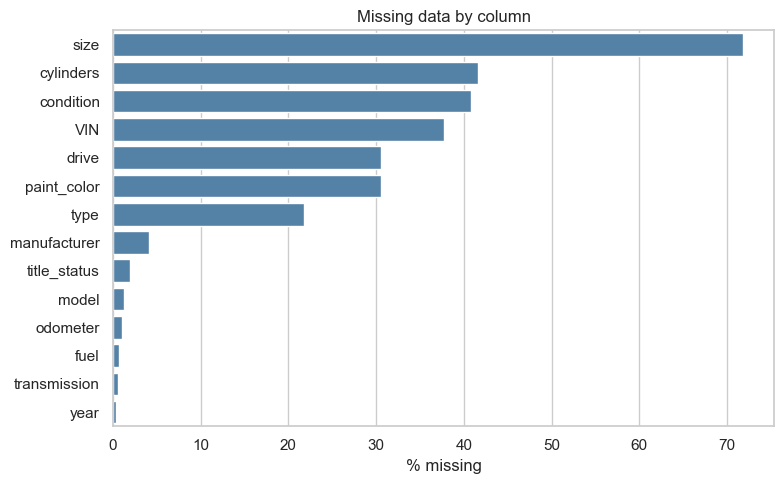

In [5]:
# Visualize missing data

fig, ax = plt.subplots(figsize=(8, 5))
missing_pct = data.isna().mean().sort_values(ascending=False) * 100
missing_pct = missing_pct[missing_pct > 0]
sns.barplot(x=missing_pct.values, y=missing_pct.index, ax=ax, color="steelblue")
ax.set_xlabel("% missing")
ax.set_ylabel("")
ax.set_title("Missing data by column")
plt.tight_layout()
plt.show()

In [6]:
data.describe()

,id,price,year,odometer
count,4.268800e+05,4.268800e+05,425675.000000,4.224800e+05
mean,7.311487e+09,7.519903e+04,2011.235191,9.804333e+04
std,4.473170e+06,1.218228e+07,9.452120,2.138815e+05
min,7.207408e+09,0.000000e+00,1900.000000,0.000000e+00
25%,7.308143e+09,5.900000e+03,2008.000000,3.770400e+04
50%,7.312621e+09,1.395000e+04,2013.000000,8.554800e+04
75%,7.315254e+09,2.648575e+04,2017.000000,1.335425e+05
max,7.317101e+09,3.736929e+09,2022.000000,1.000000e+07


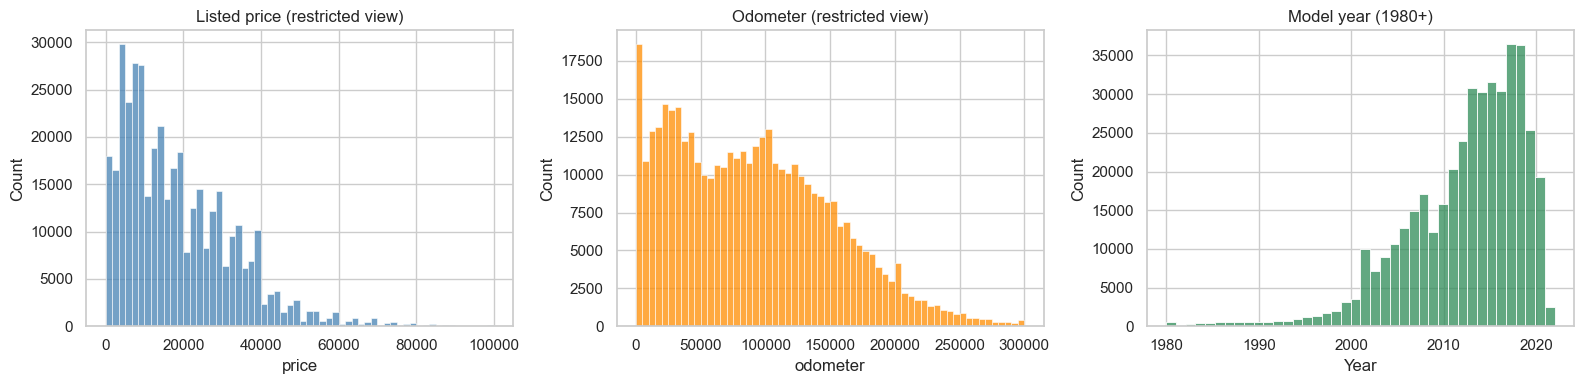

In [7]:
# In general list price, year and odometer are the most important numeric features for predicting the price of a used car. 
# These 3 features do have some outliers, so we will visualize them in a restricted view to get a better sense of their distributions.

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data.loc[data['price'].between(1, 100000), 'price'], bins=60, ax=axes[0], color="steelblue")
axes[0].set_title('Listed price (restricted view)')


sns.histplot(data.loc[data['odometer'].between(0, 300000), 'odometer'], bins=60, ax=axes[1], color="darkorange")
axes[1].set_title('Odometer (restricted view)')

sns.histplot(data.loc[data["year"] >= 1980, "year"], bins=40, ax=axes[2], color="seagreen")
axes[2].set_title("Model year (1980+)")
axes[2].set_xlabel("Year")


plt.tight_layout()
plt.show()



In [8]:
# Cardinality of categorical columns
cat_cols = ["region", "manufacturer", "model", "condition", "cylinders", "fuel",
            "title_status", "transmission", "drive", "size", "type", "paint_color", "state"]
print (pd.DataFrame({"n_unique": data[cat_cols].nunique()}).sort_values("n_unique", ascending=False))

for col in cat_cols:
    print(f'\n{col}:')
    display(data[col].value_counts(dropna=False).head(10).to_frame('count'))

              n_unique
model            29649
region             404
state               51
manufacturer        42
type                13
paint_color         12
cylinders            8
condition            6
title_status         6
fuel                 5
size                 4
transmission         3
drive                3

region:


,count
region,
columbus,3608
jacksonville,3562
spokane / coeur d'alene,2988
eugene,2985
fresno / madera,2983
orlando,2983
bend,2982
omaha / council bluffs,2982
new hampshire,2981



manufacturer:


,count
manufacturer,
ford,70985
chevrolet,55064
toyota,34202
honda,21269
nissan,19067
jeep,19014
ram,18342
NaN,17646
gmc,16785



model:


...

,count
type,
NaN,92858
sedan,87056
SUV,77284
pickup,43510
truck,35279
other,22110
coupe,19204
hatchback,16598
wagon,10751



paint_color:


,count
paint_color,
NaN,130203
white,79285
black,62861
silver,42970
blue,31223
red,30473
grey,24416
green,7343
custom,6700



state:


,count
state,
ca,50614
fl,28511
tx,22945
ny,19386
oh,17696
or,17104
mi,16900
nc,15277
wa,13861


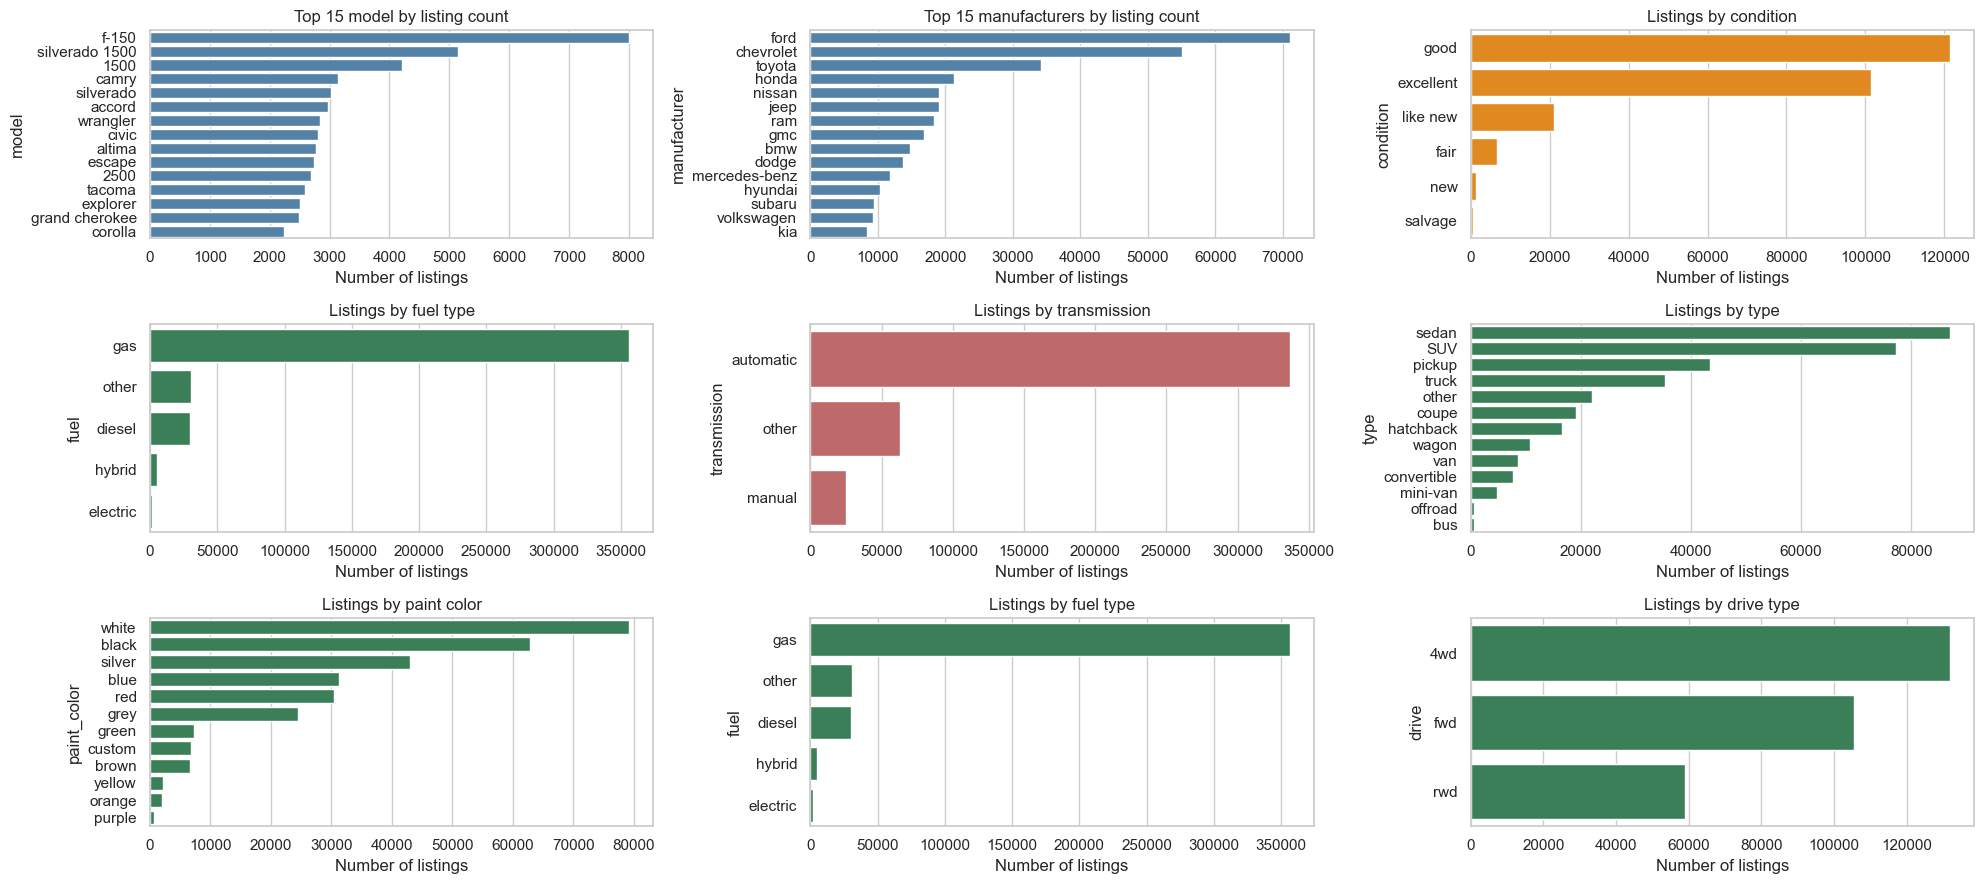

In [9]:
# Few plots to visulize the listing based on the categorical features. We will visualize the distribution of price based on the categorical features.   
fig, axes = plt.subplots(3, 3, figsize=(20, 9))

""" 
Fo the categorical features, we will visualize the distribution of listings  based on the categorical features. 
For categorical features with high cardinality, we will visualize the top 15 categories based on the listing count.

model            29649 
region             404  
state               51
manufacturer        42
type                13
paint_color         12
cylinders            8
condition            6
title_status         6
fuel                 5
size                 4
transmission         3
drive                3
"""

# Top 15 model by listing count
top_model = data["model"].value_counts().head(15)
sns.barplot(x=top_model.values, y=top_model.index, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Top 15 model by listing count")
axes[0, 0].set_xlabel("Number of listings")

# Top 15 manufacturers by listing count
top_manufacturers = data["manufacturer"].value_counts().head(15)
sns.barplot(x=top_manufacturers.values, y=top_manufacturers.index, ax=axes[0, 1], color="steelblue")
axes[0, 1].set_title("Top 15 manufacturers by listing count")
axes[0, 1].set_xlabel("Number of listings")

sns.countplot(data=data, y="condition", order=data["condition"].value_counts().index, ax=axes[0, 2], color="darkorange")
axes[0, 2].set_title("Listings by condition")
axes[0, 2].set_xlabel("Number of listings")

sns.countplot(data=data, y="fuel", order=data["fuel"].value_counts().index, ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Listings by fuel type")
axes[1, 0].set_xlabel("Number of listings")

sns.countplot(data=data, y="transmission", order=data["transmission"].value_counts().index, ax=axes[1, 1], color="indianred")
axes[1, 1].set_title("Listings by transmission")
axes[1, 1].set_xlabel("Number of listings")

# Top 15 types by listing count
sns.countplot(data=data, y="type", order=data["type"].value_counts().index, ax=axes[1, 2], color="seagreen")
axes[1, 2].set_title("Listings by type")
axes[1, 2].set_xlabel("Number of listings")

# Top 15 paint colors by listing count
sns.countplot(data=data, y="paint_color", order=data["paint_color"].value_counts().index, ax=axes[2, 0], color="seagreen")
axes[2, 0].set_title("Listings by paint color")
axes[2, 0].set_xlabel("Number of listings")

# Top 15 fuels by listing count
sns.countplot(data=data, y="fuel", order=data["fuel"].value_counts().index, ax=axes[2, 1], color="seagreen")
axes[2, 1].set_title("Listings by fuel type")
axes[2, 1].set_xlabel("Number of listings")

# Top 15 drives by listing count
sns.countplot(data=data, y="drive", order=data["drive"].value_counts().index, ax=axes[2, 2], color="seagreen")
axes[2, 2].set_title("Listings by drive type")
axes[2, 2].set_xlabel("Number of listings")

plt.tight_layout()
plt.show()

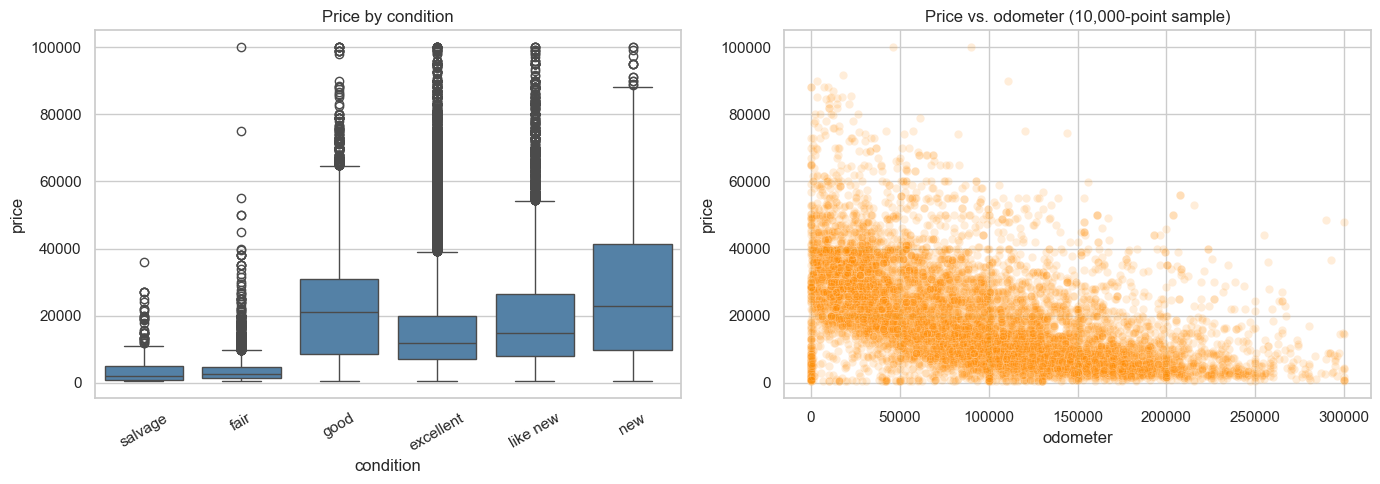

In [10]:
# How does price (within a restricted  range) relate to  conditon and odometer
plot_df = data[data["price"].between(500, 100000) & data["odometer"].between(0, 300000)]

fig, axes = plt.subplots(1,2, figsize=(14, 5))

sns.boxplot(data=plot_df, x="condition", y="price",
            order=["salvage", "fair", "good", "excellent", "like new", "new"],
            ax=axes[0], color="steelblue")
axes[0].set_title("Price by condition")
axes[0].tick_params(axis="x", rotation=30)

sns.scatterplot(data=plot_df.sample(10000, random_state=42), x="odometer", y="price",
                 alpha=0.15, ax=axes[1], color="darkorange")
axes[1].set_title("Price vs. odometer (10,000-point sample)")



plt.tight_layout()
plt.show()

### Data-quality observations

-The dataset has 426,880 listings and 18 columns; `price` is our regression target.

- Unreliable attributes -  `id` and `VIN` (mostly missing / unique per car), and `model` (nearly 30,000 free-text values — too high-cardinality and noisy).

- `region`, 'state' can encode geography, but location effects may be unstable State is retained region will be ignored

- `size` (72% missing), `cylinders` (42%), `condition` (41%), `drive` (31%), and `paint_color` (31%) have substantial missingness. Rather than dropping these rows (which would discard most of the data), we'll encode missing as its own `"unknown"` category. 

- `price`, `odometer`, and `year` all contain extreme,   outliers (e.g., a max price of $3.7B, a max odometer of 10,000,000 miles, and listings from the year 1900) that are clearly data-entry errors and must be filtered out before modeling.

- `model` is high-cardinality. Rare model names are grouped as `Other` to control dimensionality and avoid overfitting.

## 3. Data Preparation

Cleaning rules are deliberately simple and auditable:

- price: $500–$100,000;
- model year: 1985 through 2022 (the dataset's latest plausible year);
- odometer: 0–300,000 miles;
- remove duplicate rows and rows missing price/year/odometer;
- create `vehicle_age` and `miles_per_year`;
- retain the 75 most frequent model labels and map all others to `Other`;
- model `log1p(price)` to reduce right skew, then transform predictions back to dollars.

Preprocessing is fitted only on training folds through scikit-learn pipelines, preventing imputation, scaling, or encoding leakage.

In [11]:
# Drop columns that are not useful predictors:
# - id: unique identifier
# - VIN: unique identifier, 38% missing
# - model: ~30,000 free-text values, too high-cardinality to encode usefully
# - region: 404 categories that largely duplicate the information in `state`

df = data.drop(columns=["id", "VIN", "model", "region"])

before = len(df)
df = df.drop_duplicates()
print(f"Dropped {before - len(df):,} duplicate rows -> {len(df):,} rows remain")

Dropped 130,218 duplicate rows -> 296,662 rows remain


In [12]:
# Filter out  outliers in price, odometer, and year.
# A dealership sells regular used cars, not antiques or salvage-yard rejects, so we
# restrict to a realistic listing range: $500-$100,000, 0-300,000 miles, and model year 1990+.
before = len(df)
df = df[
    df["price"].between(500, 100_000)
    & df["odometer"].between(0, 300_000)
    & df["year"].between(1990, 2026)
]
print(f"Dropped {before - len(df):,} outlier rows -> {len(df):,} rows remain "
      f"({len(df) / len(data):.0%} of the original dataset)")

Dropped 40,635 outlier rows -> 256,027 rows remain (60% of the original dataset)


In [13]:
# Drop the small number of rows missing low-missingness fields we need for modeling; this will not shrink the dataset
before = len(df)
df = df.dropna(subset=["manufacturer", "odometer", "year", "fuel", "transmission", "title_status"])
print(f"Dropped {before - len(df):,} rows with missing key fields -> {len(df):,} rows remain")

# For high-missingness categorical columns, treat "missing" as its own informative category.
high_missing_cats = ["condition", "cylinders", "drive", "size", "type", "paint_color"]
df[high_missing_cats] = df[high_missing_cats].fillna("unknown")

# Normalize the cylinders text (e.g. "8 cylinders" -> "8") so the category labels are cleaner.
df["cylinders"] = df["cylinders"].str.replace(" cylinders", "", regex=False)

df.isna().sum()

Dropped 13,816 rows with missing key fields -> 242,211 rows remain


price           0
year            0
manufacturer    0
condition       0
cylinders       0
fuel            0
odometer        0
title_status    0
transmission    0
drive           0
size            0
type            0
paint_color     0
state           0
dtype: int64

In [14]:
# Feature engineering: convert model year into vehicle age, which is more directly
# interpretable ("each additional year of age") than a year value.
reference_year = int(df["year"].max()) + 1 
df["age"] = reference_year - df["year"]
df[["year", "age"]].describe()

,year,age
count,242211.000000,242211.000000
mean,2011.758446,11.241554
std,6.035503,6.035503
min,1990.000000,1.000000
25%,2008.000000,6.000000
50%,2013.000000,10.000000
75%,2017.000000,15.000000
max,2022.000000,33.000000


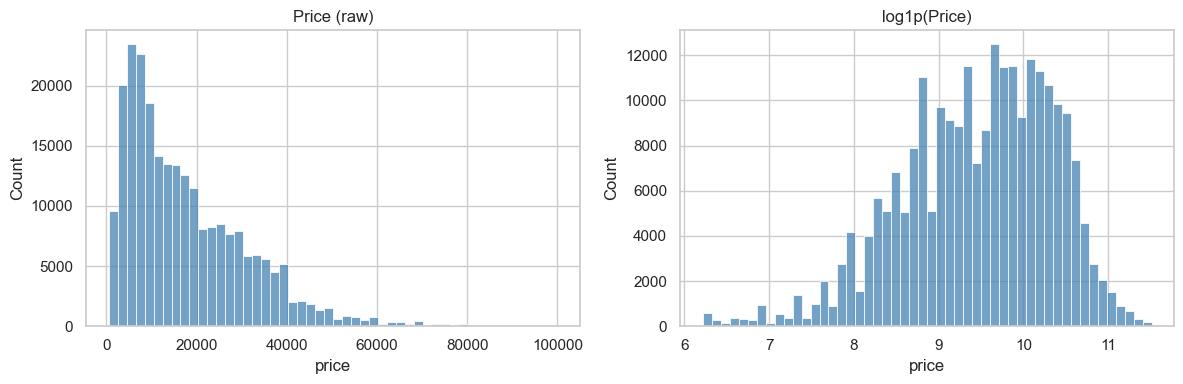

In [15]:
# Price is heavily right-skewed (a $5k gap matters a lot more on a $10k car than a $80k
# car), so we model log(price). This also keeps the linear model's constant-percentage-effect
# assumption closer to how car pricing actually works, and lets us interpret coefficients as
# approximate percentage changes in price.
#
# We us log1p instead of log to avoid issues with zero prices (which we have filtered out, but it's a good habit).  
# In reverse we can use expm1 to get back the original price from log1p(price).
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Price (raw)")
sns.histplot(np.log1p(df["price"]), bins=50, ax=axes[1], color="steelblue")
axes[1].set_title("log1p(Price)")
plt.tight_layout()
plt.show()

df["log_price"] = np.log1p(df["price"])

In [16]:

# Prepearing the data for modeling: splitting into training and test sets, and defining the features and target variable.
# Like to run the test with regualr price and compare the results with  log(1+price) to see which one performs better.    

from sklearn.model_selection import train_test_split

cat_features = ["manufacturer", "condition", "cylinders", "fuel", "title_status",
                "transmission", "drive", "size", "type", "paint_color", "state"]
num_features = ["odometer", "age"]

X = df[cat_features + num_features]
y = df["log_price"]

X_log_price_train, X_log_price_test, y_log_price_train, y_log_price_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Log Price - Train: {X_log_price_train.shape}, Test: {X_log_price_test.shape}")  

# Test splitting with price as target variable   jut for comparison with log(1+price) as target variable.
y_raw_price  = df["price"]
X_raw_price_train, X_raw_price_test, y_raw_price_train, y_raw_price_test = train_test_split(X, y_raw_price, test_size=0.2, random_state=42)
print(f"Raw Price - Train: {X_raw_price_train.shape}, Test: {X_raw_price_test.shape}")


Log Price - Train: (193768, 13), Test: (48443, 13)
Raw Price - Train: (193768, 13), Test: (48443, 13)


In [17]:
#Check for NA values
df.isna().sum()

price           0
year            0
manufacturer    0
condition       0
cylinders       0
fuel            0
odometer        0
title_status    0
transmission    0
drive           0
size            0
type            0
paint_color     0
state           0
age             0
log_price       0
dtype: int64

In [18]:
# Define the preprocessing pipelines for numeric and categorical features.
# For linear models, we will use one-hot encoding for categorical features, while for tree-based models, we will use ordinal encoding. 
# We will also impute missing values for both numeric and categorical features. In this case  this may not be necessary since we have already filtered out the rows with missing values, but it is a good practice to include it in the pipeline.
# but added as a good practice to include it in the pipeline.
# For categorical features, we will use  mon_frequency=25 in OneHotEncoder to avoid creating too many dummy variables for rare categories, which can lead to overfitting and increased computational cost.


linear_preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')), 
        ('scaler', StandardScaler())
    ]), num_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=25))
    ]), cat_features)
])

tree_preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    ]), cat_features)
])

**Data preparation summary:** 
- starting from 426,880 listings, we removed unreliable identifier columns (`id`, `VIN`), the too-high-cardinality `model` and `region` columns, exact duplicates, and rows with outliers `price`/`odometer`/`year` values or missing key fields. This left **242,431** listings (57% of the original data). 
- We engineered `age` from `year`, filled high-missingness categoricals with an `"unknown"` category rather than dropping them, and log-transformed `price` to address its right skew. 
- A `ColumnTransformer` one-hot-encodes the 11 categorical features and standardizes the 2 numeric features, ready to feed into `sklearn` regression pipelines.

## 4. Modeling

The median baseline establishes a minimum standard. Ordinary least squares tests a simple linear relationship. Ridge and Lasso add L2 and L1 regularization respectively; their penalty strengths are chosen by 3-fold cross-validation. Based on parameters needs to be tuned and size of dataset, use GridSearchCV.
At the time of my attempt to this we had covered ensemble methods in the class. So adding Random Forest as a  nonlinear comparison. Also, while invesigating I came across log transformation of y values.  Just for experimenting adding the modelling with and without log transformation. 

Final model comparison is performed in original dollars on the untouched holdout set.

In [19]:
cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

models = {
    'Median baseline': Pipeline([
        ('prep', linear_preprocessor),
        ('model', DummyRegressor(strategy='median'))
    ]),
    'Linear regression': Pipeline([
        ('prep', linear_preprocessor),
        ('model', LinearRegression())
    ]),
    'Ridge': GridSearchCV(
        Pipeline([('prep', linear_preprocessor), ('model', Ridge())]),
        {'model__alpha': [0.1, 1.0, 10.0, 100.0, 1000.0]},
        cv=cv, scoring='neg_mean_absolute_error', n_jobs=-1
    ),
    'Lasso': GridSearchCV(
        Pipeline([('prep', linear_preprocessor),
                  ('model', Lasso(max_iter=3000, selection='random', random_state=RANDOM_STATE))]),
        {'model__alpha': [0.00001, 0.0001, 0.001, 0.01]},
        cv=cv, scoring='neg_mean_absolute_error', n_jobs=-1
    ),
    'Random forest': Pipeline([
        ('prep', tree_preprocessor),
        ('model', RandomForestRegressor(
            n_estimators=140, min_samples_leaf=3, max_features=0.75,
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ])
}

def dollar_metrics_log_price(y_true_log, y_pred_log):
    actual = np.expm1(y_true_log)
    pred = np.maximum(0, np.expm1(y_pred_log))
    return {
        'MAE ($)': mean_absolute_error(actual, pred),
        'RMSE ($)': mean_squared_error(actual, pred) ** 0.5,
        'R2': r2_score(actual, pred)
    }, actual, pred

results_log_price, predictions_log_price = [], {}
for name, estimator in models.items():
    print(f'Fitting {name}...')
    estimator.fit(X_log_price_train, y_log_price_train)
    pred_log = estimator.predict(X_log_price_test)
    metrics, actual, pred = dollar_metrics_log_price(y_log_price_test, pred_log)
    metrics['Model'] = name
    results_log_price.append(metrics)
    predictions_log_price[name] = pred

results_log_price_df = pd.DataFrame(results_log_price).set_index('Model').sort_values('MAE ($)')
display(results_log_price_df.style.format({'MAE ($)': '${:,.0f}', 'RMSE ($)': '${:,.0f}', 'R2': '{:.3f}'}))
print('Best Ridge parameters:', models['Ridge'].best_params_)
print('Best Lasso parameters:', models['Lasso'].best_params_)



Fitting Median baseline...
Fitting Linear regression...
Fitting Ridge...
Fitting Lasso...
Fitting Random forest...


,MAE ($),RMSE ($),R2
Model,,,
Random forest,"$3,180","$5,734",0.830
Ridge,"$4,653","$7,628",0.698
Lasso,"$4,653","$7,634",0.698
Linear regression,"$4,655","$7,640",0.697
Median baseline,"$10,575","$14,411",-0.077


Best Ridge parameters: {'model__alpha': 10.0}
Best Lasso parameters: {'model__alpha': 1e-05}


In [20]:
# Now train the models with raw price as target variable and compare the results with log(1+price) as target variable.

models_raw_price = {
    'Median baseline': Pipeline([
        ('prep', linear_preprocessor),
        ('model', DummyRegressor(strategy='median'))
    ]),
    'Linear regression': Pipeline([
        ('prep', linear_preprocessor),
        ('model', LinearRegression())
    ]),
    'Ridge': GridSearchCV(
        Pipeline([('prep', linear_preprocessor), ('model', Ridge())]),
        {'model__alpha': [0.1, 1.0, 10.0, 100.0, 1000.0]},
        cv=cv, scoring='neg_mean_absolute_error', n_jobs=-1
    ),
    'Lasso': GridSearchCV(
        Pipeline([('prep', linear_preprocessor),
                  ('model', Lasso(max_iter=3000, selection='random', random_state=RANDOM_STATE))]),
        {'model__alpha': [0.00001, 0.0001, 0.001, 0.01]},
        cv=cv, scoring='neg_mean_absolute_error', n_jobs=-1
    ),
    'Random forest': Pipeline([
        ('prep', tree_preprocessor),
        ('model', RandomForestRegressor(
            n_estimators=140, min_samples_leaf=3, max_features=0.75,
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ])
}

def dollar_metrics_raw_price(y_true, y_pred):
    actual = y_true
    pred = y_pred
    return {
        'MAE ($)': mean_absolute_error(actual, pred),
        'RMSE ($)': mean_squared_error(actual, pred) ** 0.5,
        'R2': r2_score(actual, pred)
    }, actual, pred


results_raw_price, predictions_raw_price = [], {}
for name, estimator in models_raw_price.items():
    print(f'Fitting {name}...')
    estimator.fit(X_raw_price_train, y_raw_price_train)
    pred_log = estimator.predict(X_raw_price_test)
    #print(f'Predictions for {name}: {pred_log[:5]}')
    metrics, actual, pred = dollar_metrics_raw_price(y_raw_price_test, pred_log)
    metrics['Model'] = name
    results_raw_price.append(metrics)
    predictions_raw_price[name] = pred

results_raw_price_df = pd.DataFrame(results_raw_price).set_index('Model').sort_values('MAE ($)')
display(results_raw_price_df.style.format({'MAE ($)': '${:,.0f}', 'RMSE ($)': '${:,.0f}', 'R2': '{:.3f}'}))
print('Best Ridge parameters:', models_raw_price['Ridge'].best_params_)
print('Best Lasso parameters:', models_raw_price['Lasso'].best_params_)

Fitting Median baseline...
Fitting Linear regression...
Fitting Ridge...
Fitting Lasso...
Fitting Random forest...


,MAE ($),RMSE ($),R2
Model,,,
Random forest,"$3,072","$5,385",0.850
Ridge,"$5,318","$7,762",0.688
Lasso,"$5,318","$7,766",0.687
Linear regression,"$5,318","$7,766",0.687
Median baseline,"$10,575","$14,411",-0.077


Best Ridge parameters: {'model__alpha': 10.0}
Best Lasso parameters: {'model__alpha': 0.01}


In [21]:
# Compare the results of the models trained with raw price as target variable and log(1+price) as target variable side by side. 
# We will create a new dataframe that combines the results of both models and display it in a tabular format.
results_combined_df = pd.concat([results_log_price_df, results_raw_price_df], axis=1, keys=['Log Price', 'Raw Price'])
results_combined_df.columns = ['_'.join(col).strip() for col in results_combined_df.columns.values]
results_combined_df   



,Log Price_MAE ($),Log Price_RMSE ($),Log Price_R2,Raw Price_MAE ($),Raw Price_RMSE ($),Raw Price_R2
Model,,,,,,
Random forest,3180.482424,5733.631035,0.829566,3072.493434,5384.763385,0.849675
Ridge,4653.188055,7628.439412,0.698305,5317.720348,7762.471404,0.687610
Lasso,4653.494418,7634.243614,0.697845,5317.849457,7765.659667,0.687353
Linear regression,4654.779307,7639.591726,0.697422,5317.877054,7765.689859,0.687351
Median baseline,10575.174391,14411.162374,-0.076701,10575.174391,14411.162374,-0.076701


**Modelling Observations**
- Target Scale Matters for Linear Models: Car prices are heavily right-skewed. Transforming the target via log(1 + price) stabilizes variance and better behaviour with outliers. 
- Trees excel on Raw Target Values: Random Forest does not require normal target distributions. Direct dollar modeling  enabled leaf nodes to average exact target values, yielding the lowest overall error ($\text{MAE} = \$3,072$).

- In coclusion -  Use Random Forest trained on raw dollars for   while   log-transformed Linear/Ridge models  can be used as quicker baselines. 

## 5. Evaluation

MAE is the primary selection metric. RMSE gives extra weight to large misses, and R² describes the share of holdout price variance explained. Residual plots check systematic error across price levels. Model-agnostic permutation importance measures the increase in error after shuffling each original feature; Ridge coefficients supplement this with directional associations.

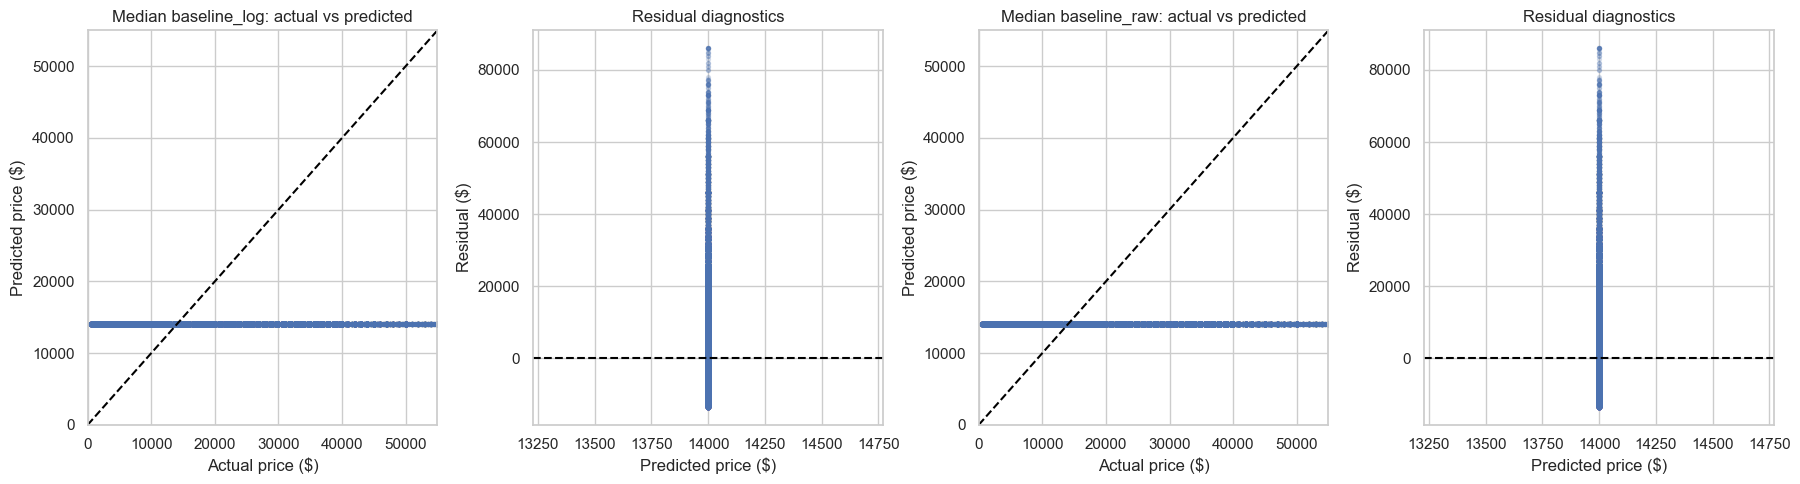

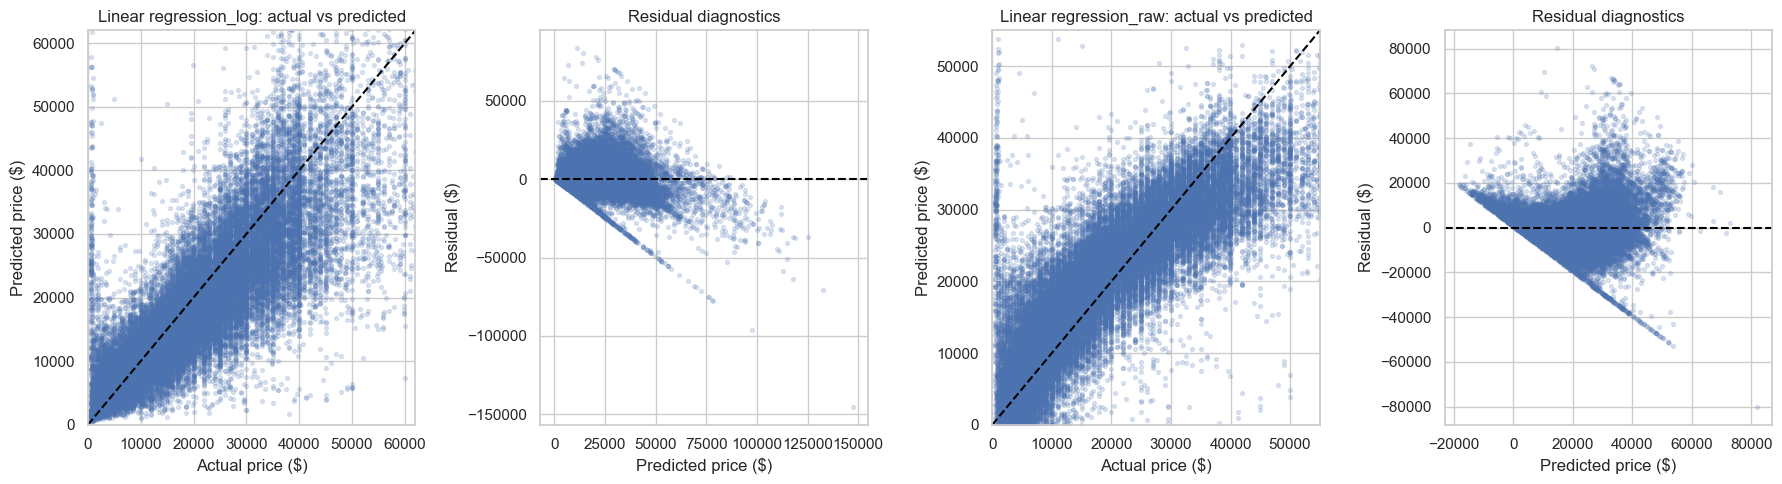

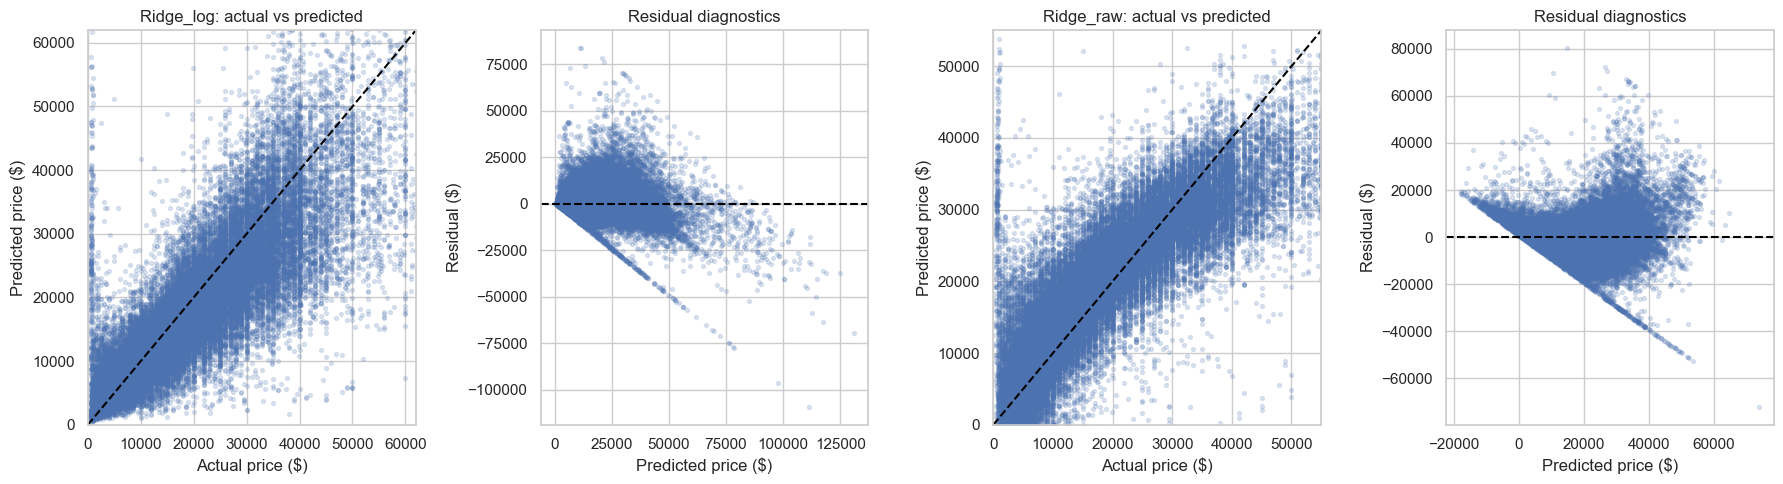

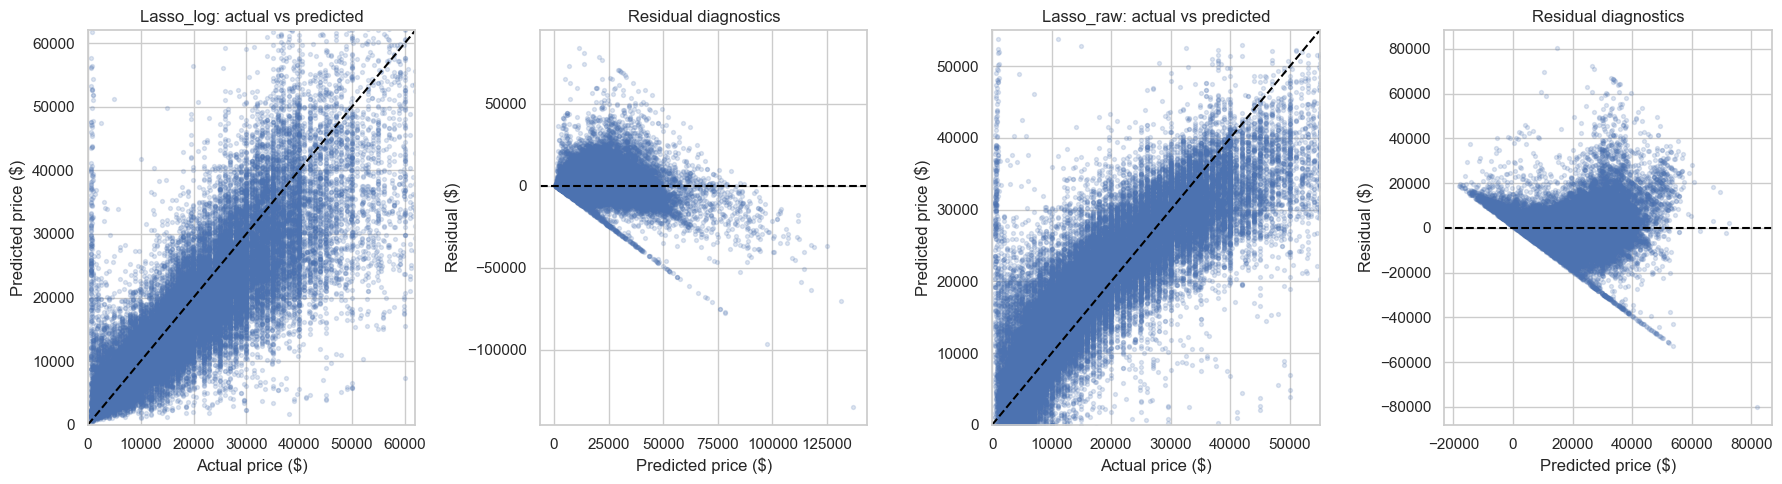

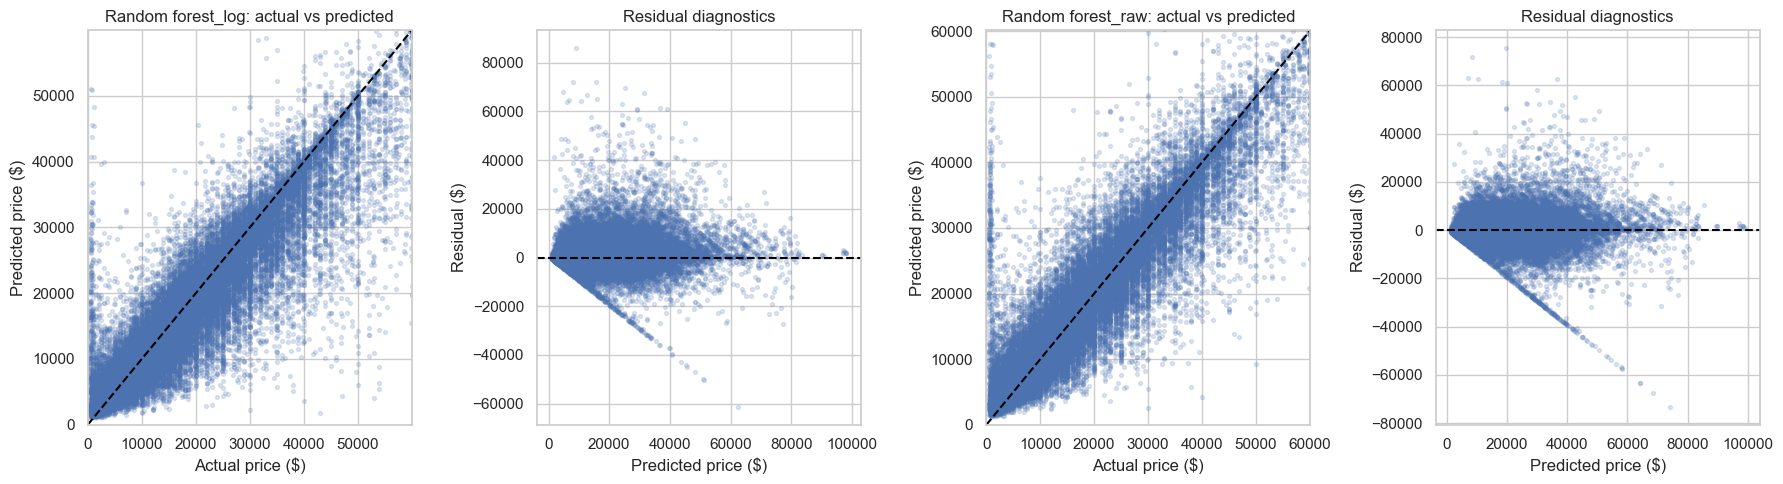

In [22]:
# Display the actual vs predicted price and residual diagnostics for all models trained with log(1+price) and raw price as target variable.

   
actual_log = np.expm1(y_log_price_test)
actual_raw = y_raw_price_test

for model_name, estimator in models.items():
 
    best_pred = predictions_log_price[model_name]
    residual = actual_log - best_pred

     
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    axes[0].scatter(actual_log, best_pred, s=8, alpha=.18)
    lim = np.percentile(np.r_[actual_log, best_pred], 99)
    axes[0].plot([0, lim], [0, lim], '--', color='black')
    axes[0].set(xlim=(0,lim), ylim=(0,lim), xlabel='Actual price ($)', ylabel='Predicted price ($)', title=f'{model_name}_log: actual vs predicted')

    axes[1].scatter(best_pred, residual, s=8, alpha=.18)
    axes[1].axhline(0, ls='--', color='black')
    axes[1].set(xlabel='Predicted price ($)', ylabel='Residual ($)', title='Residual diagnostics')

    best_pred = predictions_raw_price[model_name]
    residual = actual_raw - best_pred

    axes[2].scatter(actual_raw, best_pred, s=8, alpha=.18)
    lim = np.percentile(np.r_[actual_raw, best_pred], 99)
    axes[2].plot([0, lim], [0, lim], '--', color='black')
    axes[2].set(xlim=(0,lim), ylim=(0,lim), xlabel='Actual price ($)', ylabel='Predicted price ($)', title=f'{model_name}_raw: actual vs predicted')

    axes[3].scatter(best_pred, residual, s=8, alpha=.18)
    axes[3].axhline(0, ls='--', color='black')
    axes[3].set(xlabel='Predicted price ($)', ylabel='Residual ($)', title='Residual diagnostics')


    plt.tight_layout(); plt.show()



Best model:  Random forest


,feature,importance,std
12,age,4939.628018,48.875728
11,odometer,2882.707845,56.472072
2,cylinders,1993.525623,56.854810
6,drive,1649.469050,40.199685
0,manufacturer,1141.497099,23.675370
3,fuel,1028.967877,36.614221
8,type,791.880167,23.103630
1,condition,287.164865,15.473749
5,transmission,282.853701,7.627083
9,paint_color,202.781701,13.483368


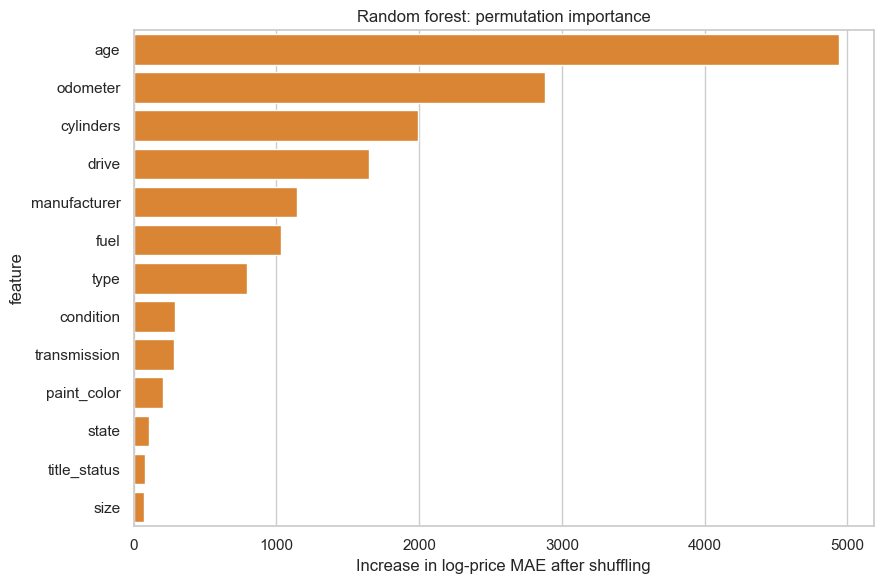

In [23]:
# Based on the results random forest model trained with raw price as target variable performed the best
# Perform Permutation Importance  to measure the global importance of features. 
# It calculates how much a model's prediction error increases when the relationship between a specific feature and the target variable is randomly broken.

best_name = results_raw_price_df.index[0]
best_model = models_raw_price[best_name]    

print ("Best model: ", best_name)

pi_n = min(5000, len(X_raw_price_test))
X_pi = X_raw_price_test.sample(pi_n, random_state=RANDOM_STATE)
y_pi = y_raw_price_test.loc[X_pi.index]

pi = permutation_importance(
    best_model, X_pi, y_pi, scoring='neg_mean_absolute_error',
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)

importance = pd.DataFrame({
    'feature': X_pi.columns,
    'importance': pi.importances_mean,
    'std': pi.importances_std
}).sort_values('importance', ascending=False)
display(importance)

plt.figure(figsize=(9, 6))
sns.barplot(data=importance, x='importance', y='feature', color='#F58518')
plt.title(f'{best_name}: permutation importance')
plt.xlabel('Increase in log-price MAE after shuffling')
plt.tight_layout(); plt.show()



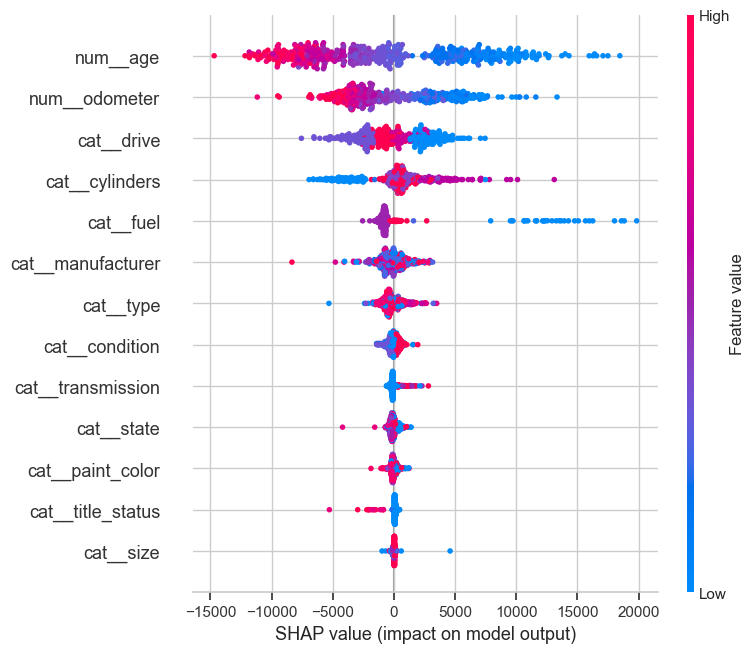

In [24]:
# Add a SHAP (SHapley Additive exPlanations)analysis to understand the contribution of each feature and directionality  to the model's predictions. We will use the SHAP library to compute SHAP values for the best model and visualize them.
# Note that this is very expenssive and may take a long time to run, so we will only use a sample of the test set for this analysis.

import shap

raw_model = best_model.named_steps['model']
X_val_sample = X_raw_price_test.sample(n=500, random_state=42)

X_raw_price_test_preprocessed = best_model.named_steps['prep'].transform(X_val_sample)

if hasattr(best_model.named_steps['prep'], 'get_feature_names_out'):
    feature_names = best_model.named_steps['prep'].get_feature_names_out()
else:
    feature_names = X_val_sample.columns.tolist()

#print (f"Feature names after preprocessing: {feature_names}")

explainer = shap.TreeExplainer(raw_model)
shap_values = explainer.shap_values(X_raw_price_test_preprocessed)

shap.summary_plot(shap_values, X_raw_price_test_preprocessed, feature_names=feature_names)




In [25]:

# Now get the top features impacting the predictions
# 
if hasattr(shap_values, "values"):
    shap_array = shap_values.values
else:
    shap_array = shap_values

# Compute mean absolute SHAP value per feature across all samples
mean_abs_shap = np.abs(shap_array).mean(axis=0)


# Create a pandas Series mapping feature names to mean SHAP impact
shap_importance = pd.Series(mean_abs_shap, index=feature_names).sort_values(ascending=False)
# Remove the prefix added by ColumnTransformer and OneHotEncoder to get the original feature names
shap_importance.index = shap_importance.index.str.split('__').str[-1]

# 4. Extract top N features
N = 10
top_n_features = shap_importance.nlargest(N)

print(f"--- Top {N} Features by Mean Absolute SHAP Value ---")
print(top_n_features)

# Extract just the feature names as a list
top_n_feature_names = top_n_features.index.tolist()
print(f"\nTop {N} Feature Name List: {top_n_feature_names}")


--- Top 10 Features by Mean Absolute SHAP Value ---
age             5866.180030
odometer        3409.261483
drive           2133.664517
cylinders       1989.587054
fuel            1586.345332
manufacturer     790.911724
type             647.319556
condition        341.364767
transmission     255.396852
state            251.848670
dtype: float64

Top 10 Feature Name List: ['age', 'odometer', 'drive', 'cylinders', 'fuel', 'manufacturer', 'type', 'condition', 'transmission', 'state']


 
 
 **Insights from the SHAP summary plot**
 - SHAP plot provides both feature impotance and the direction of the effect of each feature on the model's predictions:
 - The most important features (ranked in y-axis) for predicting the price of a used car are age, odometer, drive and cyclinder
 - X-axis shows the SHAP value, which represents the impact of each feature on the model's output (predicted price)
 - Red dots represent higher feature values, while blue dots represent lower feature values. 
   For example, a higher age (red) leads to a lower predicted price (negative SHAP value), while a lower age (blue) leads to a higher predicted price (positive SHAP value).
 

## 6. Deployment: Findings and Recommendations

### What the dealership should act on

-  Vehicle age is the single largest influence on valuation, driving rapid depreciation across inventory. Dealerships should implement strict aging thresholds to markdown or wholesale older stock before margins erode.
-  Mileage ranks as the second most critical price driver, with values dropping sharply at key usage milestones. Acquisition teams must appraise cars aggressively near these thresholds while highlighting low-mileage benefits in digital marketing.
-  Drivetrain, cylinder count, and fuel type heavily outweigh brand and body style in determining secondary market worth. Inventory acquisition should   prioritize these high-demand mechanical configurations to maximize pricing power.
- Cosmetic condition ranks lower in overall impact than core mechanical and structural attributes like age or mileage. Managers should limit heavy spending on minor cosmetic fixes and instead direct capital toward powertrain soundness and desirable vehicle specifications.

### Operationalization

- The above model provides a decent practical benchmark with limitations. 
- Refit on recent sold-price data if available; advertised prices are only a proxy.
- Track monthly MAE by price band, age, manufacturer, and state to detect drift and weak segments.


### Limitations and next steps

- The data omitsactual sale price, accident history, trim/options, service records, number of owners, and days on market.
- Also we need to consider the other  conditions. For e.g. current gas prices are driving  hybrid car proice higher even more than electric. Expiry of electric car incentives etc. 
   